In [25]:
%pip install openplay

Defaulting to user installation because normal site-packages is not writeable

[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [1]:
import openplay as op
import pandas as pd

all_shots = []
op.competitions()
# Collect data from 2016/17 to 2025/26 season 
for season_year in range(16,26):
    season = f"{str(season_year)}{str(season_year + 1)}"
    shots = op.shots("esp", season)
    print(f"Collected {len(shots)} shots")
    all_shots.append(shots)
    

esp_shots = pd.concat(all_shots, ignore_index=True)

print(f"Total shots: {len(esp_shots)}")

esp_shots.to_csv("esp_shots_2016_2025.csv", index=False)

Collected 9167 shots
Collected 9194 shots
Collected 9273 shots
Collected 8615 shots
Collected 8132 shots


C:\Users\Jordan\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\openplay\api.py:167: CoverageWarning: 1 played match(es) in this selection have no event data; see known_gaps()
  coverage_report(comp, season, warn=True)


Collected 8958 shots
Collected 9392 shots
Collected 9335 shots
Collected 9065 shots
Collected 9510 shots
Total shots: 90641


# Question 1: How does shot location affect the probability of scoring?

In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

shots = pd.read_csv("esp_shots_2016_2025.csv")

# Exclude own goals
shots = shots[~shots["is_own_goal"]].copy()
shots["is_goal"] = shots["is_goal"].astype(int)

# Divide the field into zones
shots["x_zone"] = pd.cut(shots["x"], bins=np.linspace(0, 100, 11))
shots["y_zone"] = pd.cut(shots["y"], bins=np.linspace(0, 100, 11))

# Calculate stats for each zone
zone_stats = shots.groupby(
    ["x_zone", "y_zone"], observed=True
).agg(
    total_shots = ("is_goal", "count"),
    goals = ("is_goal", "sum"),
    avg_xg = ("xg", "mean")
)

zone_stats["conversion_rate"] = (
    zone_stats["goals"] / zone_stats["total_shots"]
)

print(zone_stats.head(10))
print(zone_stats.tail(10))

                            total_shots  goals  avg_xg  conversion_rate
x_zone       y_zone                                                    
(20.0, 30.0] (30.0, 40.0]             1      0     NaN              0.0
             (50.0, 60.0]             2      0     NaN              0.0
             (70.0, 80.0]             1      0     NaN              0.0
             (90.0, 100.0]            1      0     NaN              0.0
(30.0, 40.0] (0.0, 10.0]              1      0     NaN              0.0
             (10.0, 20.0]             3      0     NaN              0.0
             (20.0, 30.0]             4      0     NaN              0.0
             (30.0, 40.0]             5      1     NaN              0.2
             (40.0, 50.0]            14      0     NaN              0.0
             (50.0, 60.0]             4      0     NaN              0.0
                             total_shots  goals    avg_xg  conversion_rate
x_zone        y_zone                                         

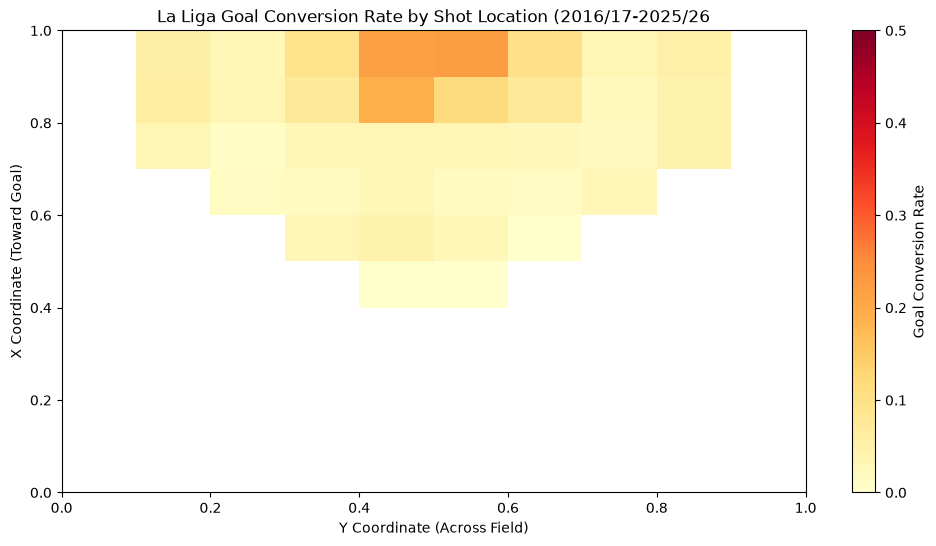

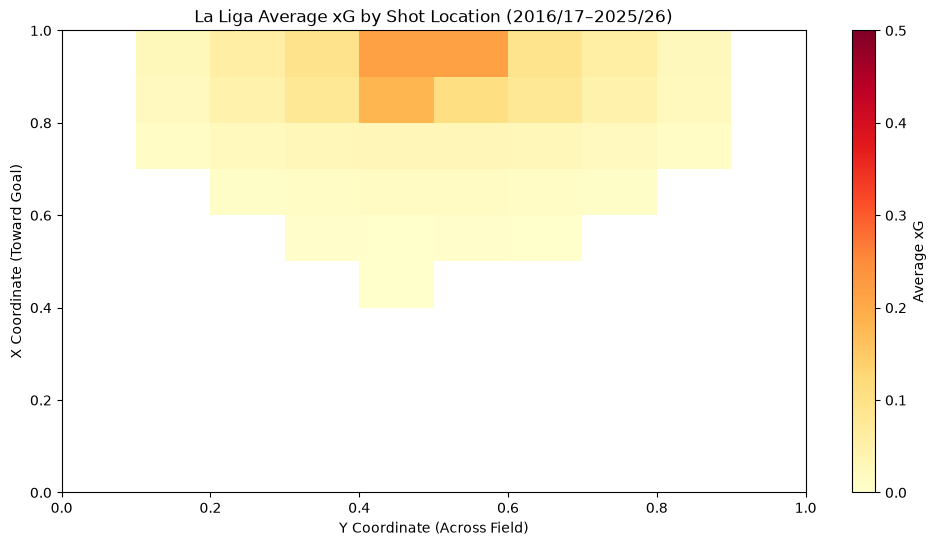

In [28]:
x_zones = shots["x_zone"].cat.categories
y_zones = shots["y_zone"].cat.categories

# Create grids using the correct categories
conversion_grid = zone_stats["conversion_rate"].unstack()
xg_grid = zone_stats["avg_xg"].unstack()
shot_count_grid = zone_stats["total_shots"].unstack()

# Reindex using the original interval categories
conversion_grid = conversion_grid.reindex(index=x_zones, columns=y_zones)
xg_grid = xg_grid.reindex(index=x_zones, columns=y_zones)

# Filter out zones with less than 30 shots
conversion_grid = conversion_grid.where(shot_count_grid >= 30)
xg_grid = xg_grid.where(shot_count_grid >= 30)


# Conversion rate heatmap
plt.figure(figsize=(12, 6))

plt.imshow(
    conversion_grid,
    origin="lower",
    cmap="YlOrRd",
    vmin=0,
    vmax=0.5,
    extent=[0, 1, 0, 1],
    aspect="auto"
)

plt.colorbar(label="Goal Conversion Rate")
plt.xlabel("Y Coordinate (Across Field)")
plt.ylabel("X Coordinate (Toward Goal)")
plt.title("La Liga Goal Conversion Rate by Shot Location (2016/17-2025/26")

plt.show()

# Average xG heatmap
plt.figure(figsize=(12, 6))

plt.imshow(
    xg_grid,
    origin="lower",
    cmap="YlOrRd",
    vmin=0,
    vmax=0.5,
    extent=[0, 1, 0, 1],
    aspect="auto"
)

plt.colorbar(label="Average xG")
plt.xlabel("Y Coordinate (Across Field)")
plt.ylabel("X Coordinate (Toward Goal)")
plt.title("La Liga Average xG by Shot Location (2016/17–2025/26)")

plt.show()

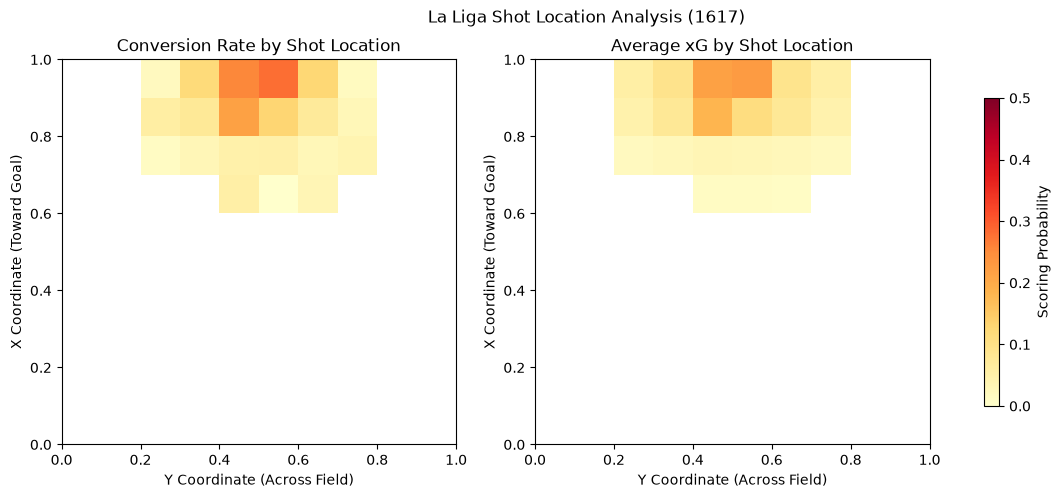

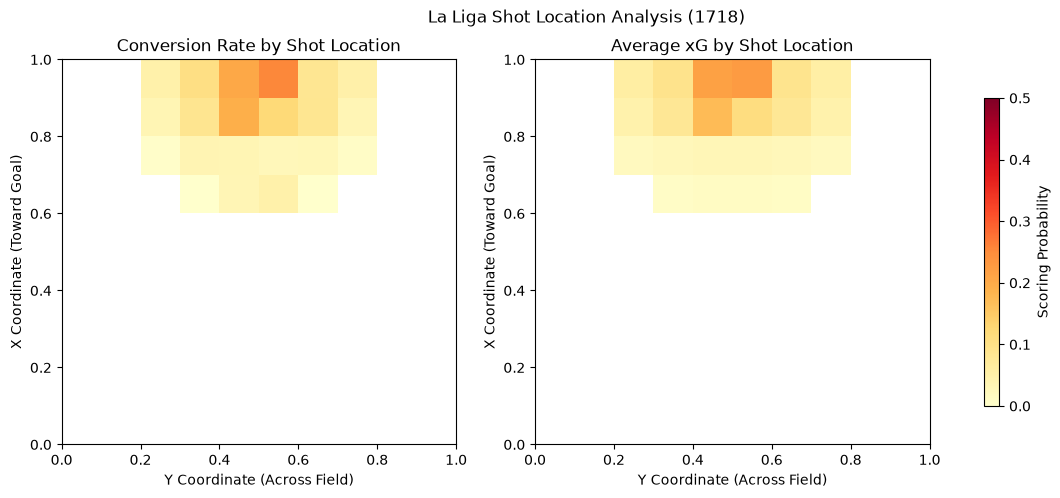

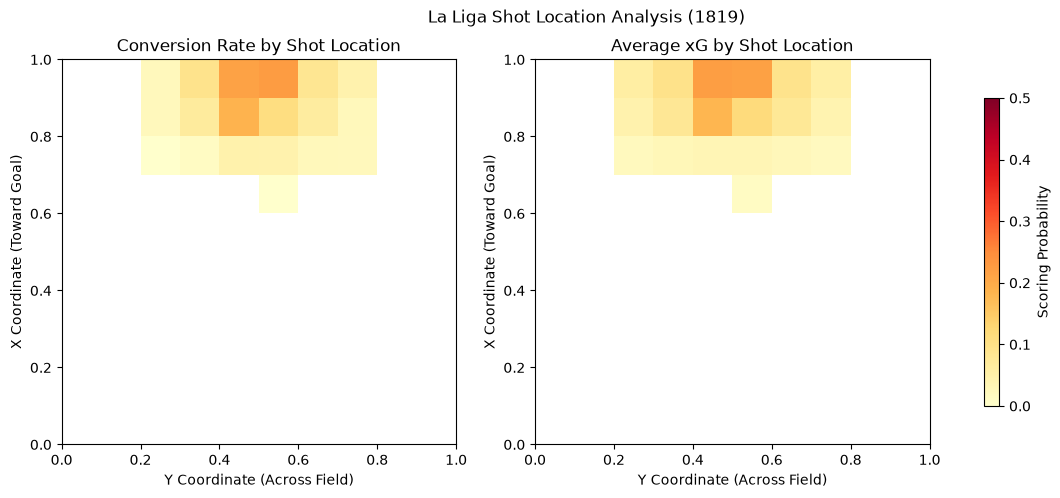

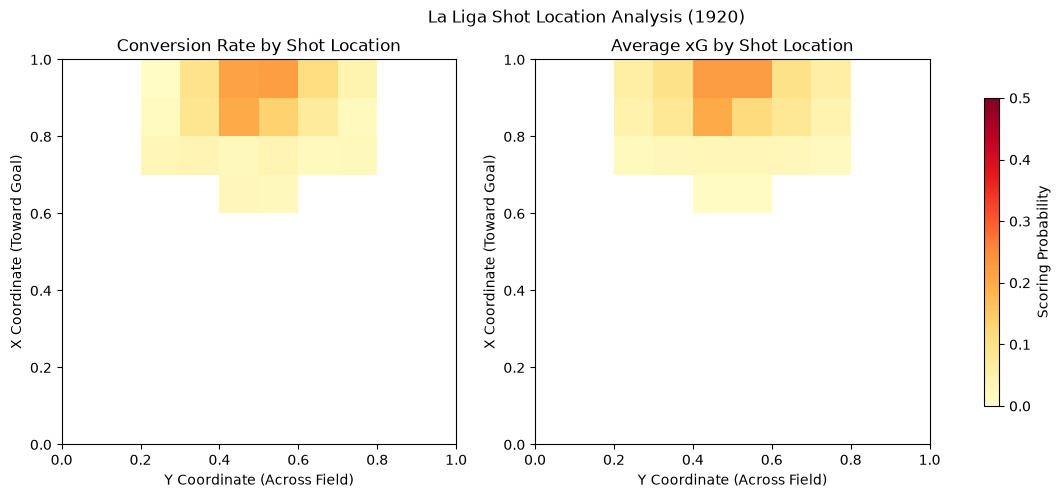

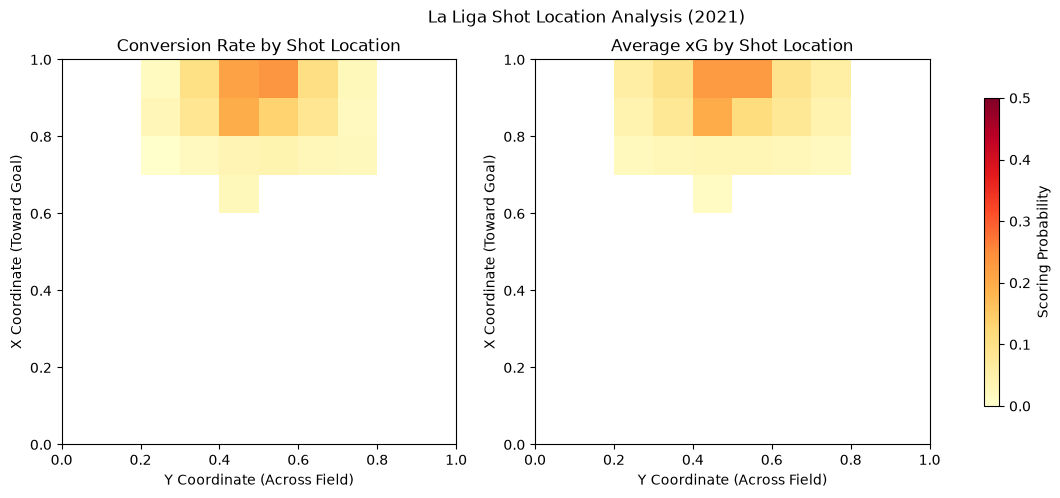

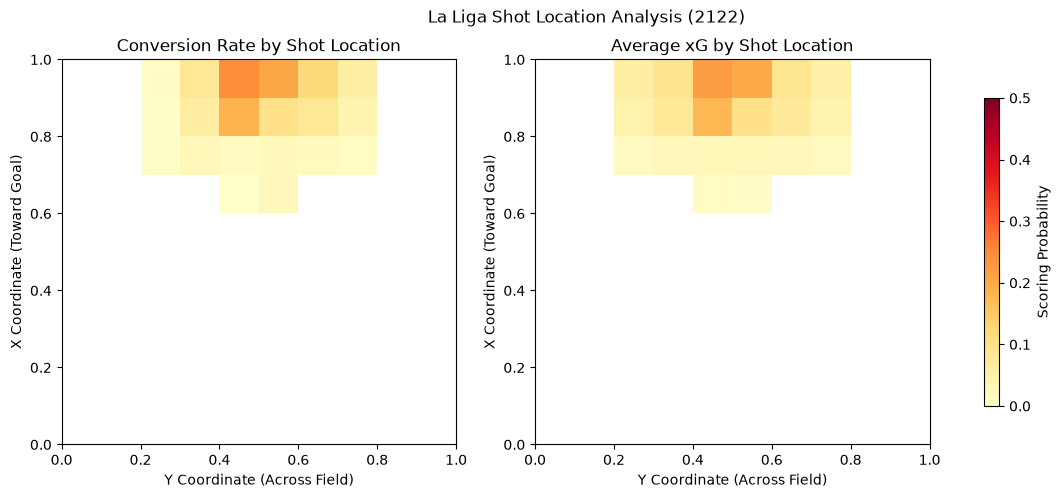

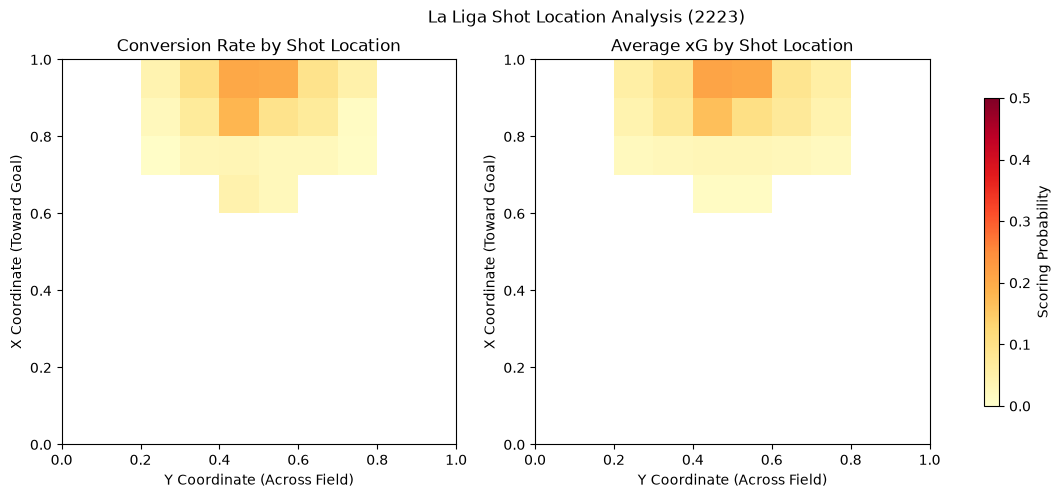

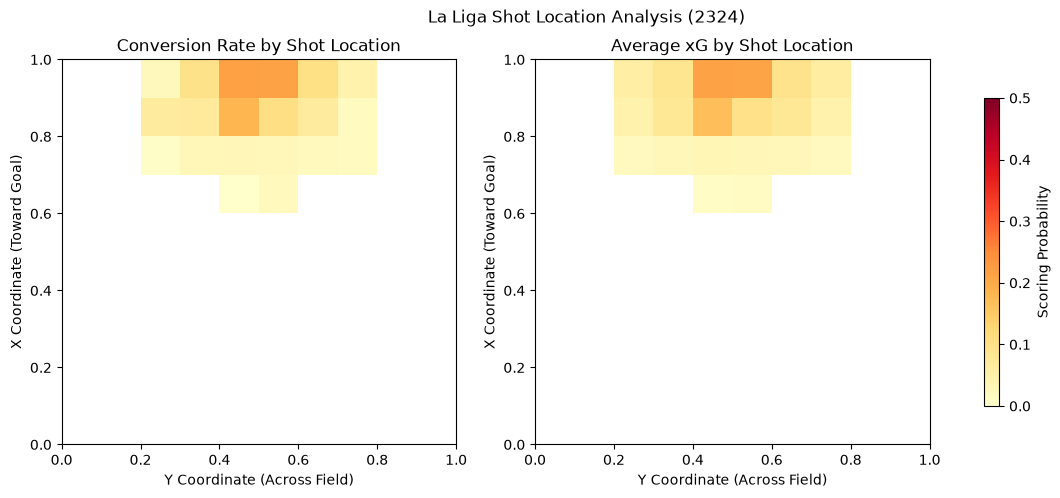

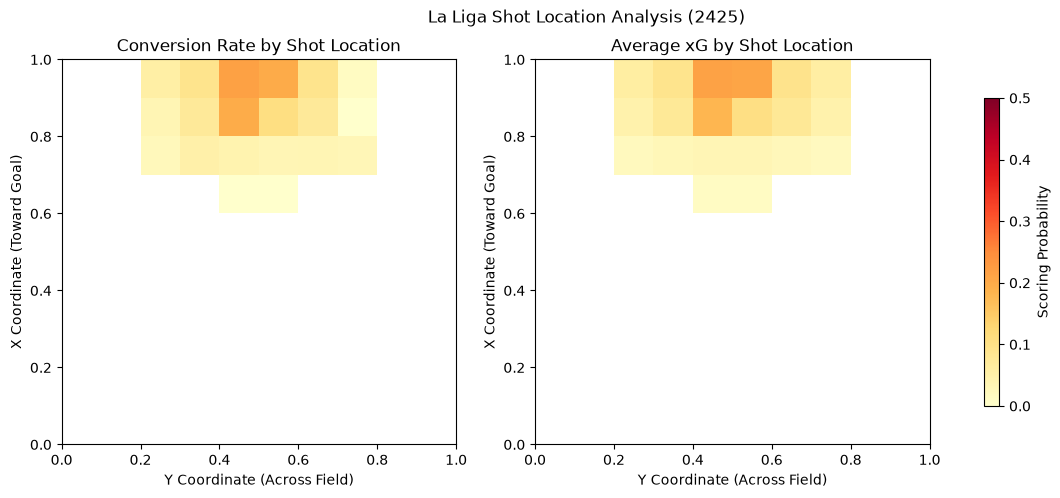

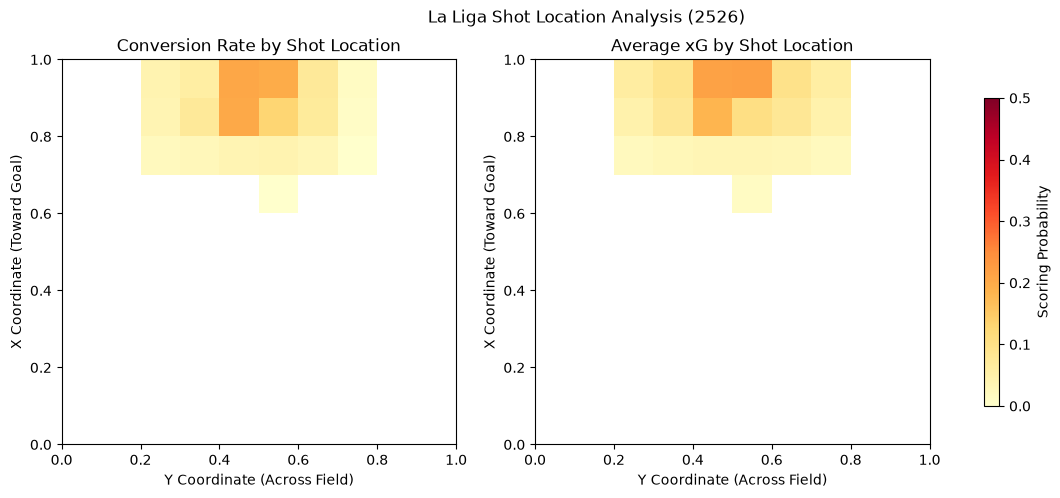

In [29]:
season_zone_stats = shots.groupby(
    ["season", "x_zone", "y_zone"],
    observed=True
).agg(
    total_shots=("is_goal", "count"),
    goals=("is_goal", "sum"),
    avg_xg=("xg", "mean")
)

season_zone_stats["conversion_rate"] = (
    season_zone_stats["goals"] / season_zone_stats["total_shots"]
)

for season in sorted(shots["season"].unique()):

    # Get statistics for this season
    season_data = season_zone_stats.loc[season]

    conversion_grid = season_data["conversion_rate"].unstack()
    xg_grid = season_data["avg_xg"].unstack()
    shot_count_grid = season_data["total_shots"].unstack()

    conversion_grid = conversion_grid.reindex(index=x_zones, columns=y_zones)
    xg_grid = xg_grid.reindex(index=x_zones, columns=y_zones)
    shot_count_grid = shot_count_grid.reindex(index=x_zones, columns=y_zones)

    # Filter out zones with less than 30 shots
    conversion_grid = conversion_grid.where(shot_count_grid >= 30)
    xg_grid = xg_grid.where(shot_count_grid >= 30)

    # Display two heatmaps side by side
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].imshow(
        conversion_grid,
        origin="lower",
        cmap="YlOrRd",
        vmin=0,
        vmax=0.5,
        extent=[0, 1, 0, 1],
        aspect="auto"
    )

    axes[0].set_title("Conversion Rate by Shot Location")
    axes[0].set_xlabel("Y Coordinate (Across Field)")
    axes[0].set_ylabel("X Coordinate (Toward Goal)")

    im = axes[1].imshow(
        xg_grid,
        origin="lower",
        cmap="YlOrRd",
        vmin=0,
        vmax=0.5,
        extent=[0, 1, 0, 1],
        aspect="auto"
    )

    axes[1].set_title("Average xG by Shot Location")
    axes[1].set_xlabel("Y Coordinate (Across Field)")
    axes[1].set_ylabel("X Coordinate (Toward Goal)")

    fig.colorbar(im, ax=axes, label="Scoring Probability", shrink=0.8)
    fig.suptitle(f"La Liga Shot Location Analysis ({season})")

    plt.show()

# Question 2: Are teams that create more chances from open play more successful than set piece dependent teams?

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("esp_shots_2016_2025.csv")

print("Total shots:", len(df))
print("Seasons:", sorted(df["season"].unique()))
print("Teams:", df["team_id"].nunique())

display(df.head())

Total shots: 90641
Seasons: [np.int64(1617), np.int64(1718), np.int64(1819), np.int64(1920), np.int64(2021), np.int64(2122), np.int64(2223), np.int64(2324), np.int64(2425), np.int64(2526)]
Teams: 31


,comp,season,match_id,event_id,event_id_sub,team_event_id,period,minute,second,expanded_minute,...,goal_mouth_z,blocked_x,blocked_y,xg,assist_player_id,assist_player,assist_type,assist_event_type,assist_event_id,xg_model
0,esp,1617,1102784,424324624,0,28,FirstHalf,1,12,1,...,18.4,NaN,NaN,0.094557,106883.0,Dani Carvajal,cross,Pass,3.403873e+08,openplay_xg_v1
1,esp,1617,1102784,485211752,0,162,FirstHalf,14,34,14,...,NaN,98.1,41.5,0.096773,93206.0,Raphaël Varane,pass,Pass,7.964611e+08,openplay_xg_v1
2,esp,1617,1102784,205849163,0,144,FirstHalf,16,47,16,...,NaN,75.9,43.7,0.017632,87094.0,Asier Illarramendi,pass,Pass,3.055395e+08,openplay_xg_v1
3,esp,1617,1102784,1070529558,0,220,FirstHalf,19,19,19,...,5.7,97.8,53.2,0.055369,91213.0,Álvaro Morata,pass,Pass,1.908895e+09,openplay_xg_v1
4,esp,1617,1102784,1331873221,0,223,FirstHalf,19,54,19,...,16.7,89.8,45.7,0.024727,NaN,NaN,NaN,NaN,NaN,openplay_xg_v1


In [5]:
# Classify shot situations
df["shot_category"] = np.where(
    df["is_penalty"] | df["is_set_piece"], "Set Piece", "Open Play"
)

# Identify goals and own goals
df["is_goal"] = df["is_goal"].astype(int)
df["is_own_goal"] = df["is_own_goal"].astype(int)

# Exclude own goals
shots = df[df["is_own_goal"] == 0].copy()

print(shots["shot_category"].value_counts())

shot_category
Open Play    65672
Set Piece    24706
Name: count, dtype: int64


In [6]:
category_stats = (
    shots.groupby("shot_category")
    .agg(
        Shots=("event_id", "count"),
        Goals=("is_goal", "sum"),
        Total_xG=("xg", "sum"),
        Average_xG=("xg", "mean")
    )
    .reset_index()
)

category_stats["Conversion_Rate"] = (
    category_stats["Goals"] / category_stats["Shots"] * 100
)

category_stats["Average_xG"] *= 100

display(category_stats.round(2))

,shot_category,Shots,Goals,Total_xG,Average_xG,Conversion_Rate
0,Open Play,65672,6911,6428.16,9.82,10.52
1,Set Piece,24706,2774,3017.64,12.23,11.23


<Figure size 900x500 with 0 Axes>

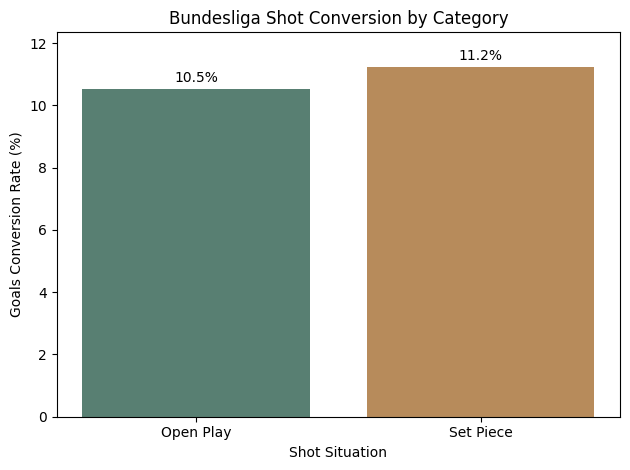

In [14]:
plt.figure(figsize=(9, 5))

colors = ['#587f72', '#b78b5b']

fig, ax = plt.subplots()
bars = ax.bar(
    category_stats["shot_category"],
    category_stats["Conversion_Rate"],
    color=colors
)
ax.bar_label(bars, padding=3, fmt='%.1f%%')
ax.set_ylim(0, max(category_stats["Conversion_Rate"]) * 1.10)

plt.title("Bundesliga Shot Conversion by Category")
plt.xlabel("Shot Situation")
plt.ylabel("Goals Conversion Rate (%)")


plt.tight_layout()
plt.show()

In [8]:
# Focus on the two main categories
main_shots = shots[
    shots["shot_category"].isin(["Open Play", "Set Piece"])
].copy()

team_stats = (
    main_shots.groupby(
        ["season", "team_id", "shot_category"]
    )
    .agg(
        Shots=("event_id", "count"),
        Goals=("is_goal", "sum"),
        xG=("xg", "sum")
    )
    .unstack(fill_value=0)
)

# Flatten the column names
team_stats.columns = [
    f"{metric}_{category.replace(' ', '_')}"
    for metric, category in team_stats.columns
]

team_stats = team_stats.reset_index()

team_stats["Total_Shots"] = (
    team_stats["Shots_Open_Play"] +
    team_stats["Shots_Set_Piece"]
)

team_stats["Set_Piece_Share"] = (
    team_stats["Shots_Set_Piece"] /
    team_stats["Total_Shots"] * 100
)

team_stats["Open_Play_Share"] = (
    team_stats["Shots_Open_Play"] /
    team_stats["Total_Shots"] * 100
)

team_stats["Set_Piece_Conversion"] = (
    team_stats["Goals_Set_Piece"] /
    team_stats["Shots_Set_Piece"].replace(0, np.nan) * 100
)

team_stats["Open_Play_Conversion"] = (
    team_stats["Goals_Open_Play"] /
    team_stats["Shots_Open_Play"].replace(0, np.nan) * 100
)

display(team_stats.head())

,season,team_id,Shots_Open_Play,Shots_Set_Piece,Goals_Open_Play,Goals_Set_Piece,xG_Open_Play,xG_Set_Piece,Total_Shots,Set_Piece_Share,Open_Play_Share,Set_Piece_Conversion,Open_Play_Conversion
0,1617,52,505,158,78,28,57.568044,22.615987,663,23.831071,76.168929,17.721519,15.445545
1,1617,53,338,149,32,21,29.905299,20.236254,487,30.595483,69.404517,14.093960,9.467456
2,1617,54,315,127,26,15,26.532960,11.185924,442,28.733032,71.266968,11.811024,8.253968
3,1617,55,329,121,35,18,31.874158,17.435626,450,26.888889,73.111111,14.876033,10.638298
4,1617,59,318,141,25,17,23.891211,17.742007,459,30.718954,69.281046,12.056738,7.861635


In [9]:
# Find the two teams in each match
match_teams = df[
    ["match_id", "season", "team_id"]
].drop_duplicates()

# Exclude games missing one team's shot records
match_teams = match_teams[
    match_teams.groupby("match_id")["team_id"]
    .transform("size").eq(2)
].copy()

# Identify each team's opponent
opponents = match_teams[["match_id", "team_id"]].merge(
    match_teams[["match_id", "team_id"]].rename(
        columns={"team_id": "opponent_id"}
    ),
    on="match_id"
)

opponents = opponents[
    opponents["team_id"] != opponents["opponent_id"]
]

# Count normal goals
normal_goals = (
    df[df["is_goal"] == 1]
    .groupby(["match_id", "team_id"])
    .size()
    .reset_index(name="normal_goals")
)

# Award own goals to the opposing team
own_goals = (
    df[df["is_own_goal"] == 1][
        ["match_id", "team_id"]
    ]
    .merge(opponents, on=["match_id", "team_id"])
    .groupby(["match_id", "opponent_id"])
    .size()
    .reset_index(name="own_goals_received")
    .rename(columns={"opponent_id": "team_id"})
)

# Reconstruct the scores
scores = (
    match_teams
    .merge(normal_goals, on=["match_id", "team_id"], how="left")
    .merge(own_goals, on=["match_id", "team_id"], how="left")
)

scores[["normal_goals", "own_goals_received"]] = (
    scores[["normal_goals", "own_goals_received"]].fillna(0)
)

scores["goals_for"] = (
    scores["normal_goals"] + scores["own_goals_received"]
)

# Attach opponent's goals
scores = scores.merge(
    scores[["match_id", "team_id", "goals_for"]].rename(
        columns={
            "team_id": "opponent_id",
            "goals_for": "goals_against"
        }
    ),
    on="match_id"
)

scores = scores[scores["team_id"] != scores["opponent_id"]]

# Calculate match points
scores["Points"] = np.select(
    [
        scores["goals_for"] > scores["goals_against"],
        scores["goals_for"] == scores["goals_against"]
    ],
    [3, 1],
    default=0
)

# Calculate points earned by each team each season
team_points = (
    scores.groupby(["season", "team_id"])
    .agg(
        Matches=("match_id", "nunique"),
        Points=("Points", "sum")
    )
    .reset_index()
)

team_points["Points_Per_Game"] = (
    team_points["Points"] / team_points["Matches"]
)

# Combine team performance with shot statistics
team_stats = team_stats.merge(
    team_points,
    on=["season", "team_id"],
    how="inner"
)

display(team_stats.head())

,season,team_id,Shots_Open_Play,Shots_Set_Piece,Goals_Open_Play,Goals_Set_Piece,xG_Open_Play,xG_Set_Piece,Total_Shots,Set_Piece_Share,Open_Play_Share,Set_Piece_Conversion,Open_Play_Conversion,Matches,Points,Points_Per_Game
0,1617,52,505,158,78,28,57.568044,22.615987,663,23.831071,76.168929,17.721519,15.445545,38,94,2.473684
1,1617,53,338,149,32,21,29.905299,20.236254,487,30.595483,69.404517,14.093960,9.467456,38,63,1.657895
2,1617,54,315,127,26,15,26.532960,11.185924,442,28.733032,71.266968,11.811024,8.253968,38,39,1.026316
3,1617,55,329,121,35,18,31.874158,17.435626,450,26.888889,73.111111,14.876033,10.638298,38,45,1.184211
4,1617,59,318,141,25,17,23.891211,17.742007,459,30.718954,69.281046,12.056738,7.861635,38,38,1.000000


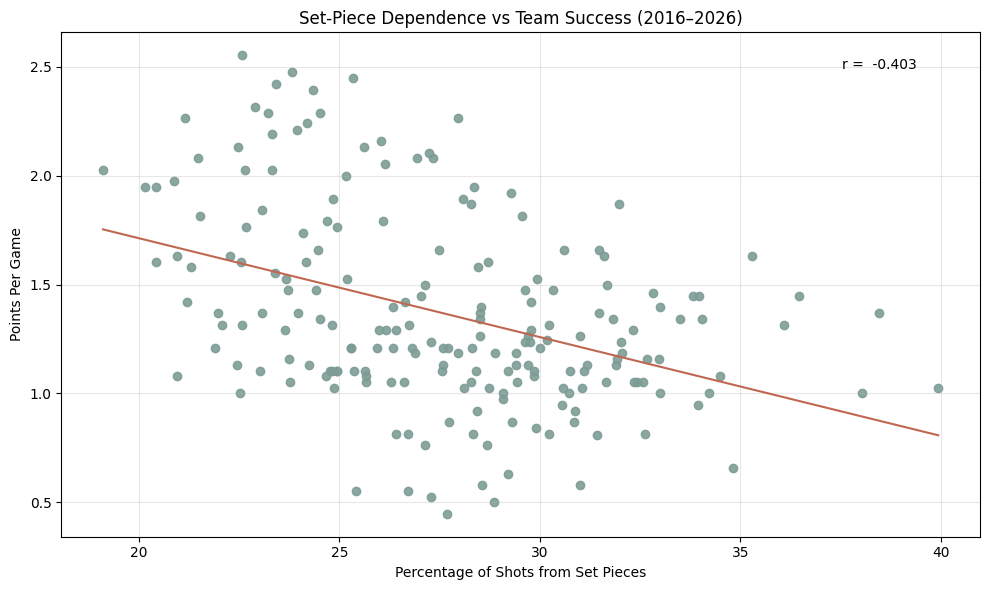

Correlation: -0.403


In [16]:
plt.figure(figsize=(10, 6))
colors = ['#7c9c95']

plt.scatter(
    team_stats["Set_Piece_Share"],
    team_stats["Points_Per_Game"],
    alpha=0.90,
    color=colors
)

# Calculate correlation
correlation = team_stats[
    ["Set_Piece_Share", "Points_Per_Game"]
].corr().iloc[0, 1]

# Add trend line
x = team_stats["Set_Piece_Share"]
y = team_stats["Points_Per_Game"]

slope, intercept = np.polyfit(x, y, 1)

x_line = np.linspace(x.min(), x.max(), 100)
plt.plot(x_line, slope * x_line + intercept, color="#c06752")

plt.title("Set-Piece Dependence vs Team Success (2016–2026)")
plt.xlabel("Percentage of Shots from Set Pieces")
plt.ylabel("Points Per Game")

plt.text(
    0.85, 0.95,
    f"r =  {correlation:.3f}",
    transform=plt.gca().transAxes,
    verticalalignment="top"
)

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Correlation:", round(correlation, 3))

In [11]:
median_share = team_stats["Set_Piece_Share"].median()

team_stats["Playstyle"] = np.where(
    team_stats["Set_Piece_Share"] >= median_share,
    "More Set-Piece Dependent",
    "More Open-Play Dependent"
)

playstyle_results = (
    team_stats.groupby("Playstyle")
    .agg(
        Teams_Seasons=("team_id", "count"),
        Avg_Points_Per_Game=("Points_Per_Game", "mean"),
        Avg_Open_Play_Goals=("Goals_Open_Play", "mean"),
        Avg_Set_Piece_Goals=("Goals_Set_Piece", "mean"),
        Avg_Set_Piece_Share=("Set_Piece_Share", "mean")
    )
)

display(playstyle_results.round(2))

,Teams_Seasons,Avg_Points_Per_Game,Avg_Open_Play_Goals,Avg_Set_Piece_Goals,Avg_Set_Piece_Share
Playstyle,,,,,
More Open-Play Dependent,100,1.53,41.88,13.51,24.40
More Set-Piece Dependent,100,1.20,27.23,14.23,30.83


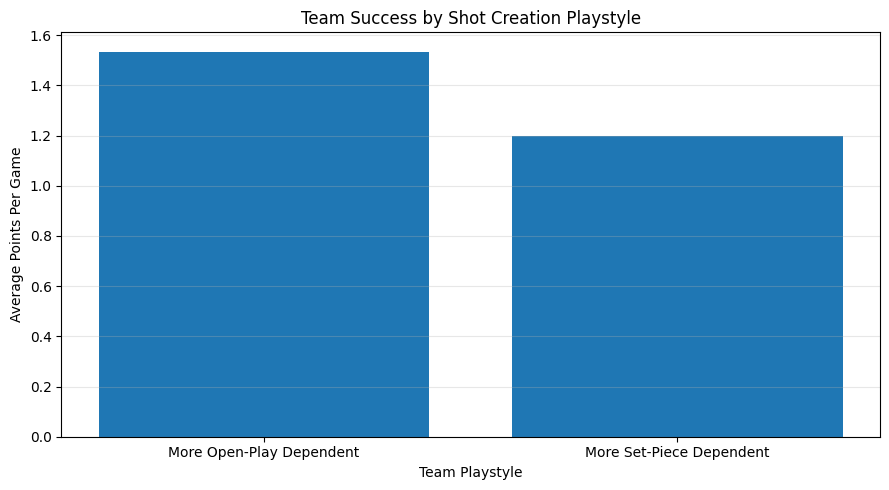

In [12]:
plt.figure(figsize=(9, 5))

plt.bar(
    playstyle_results.index,
    playstyle_results["Avg_Points_Per_Game"]
)

plt.title("Team Success by Shot Creation Playstyle")
plt.xlabel("Team Playstyle")
plt.ylabel("Average Points Per Game")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


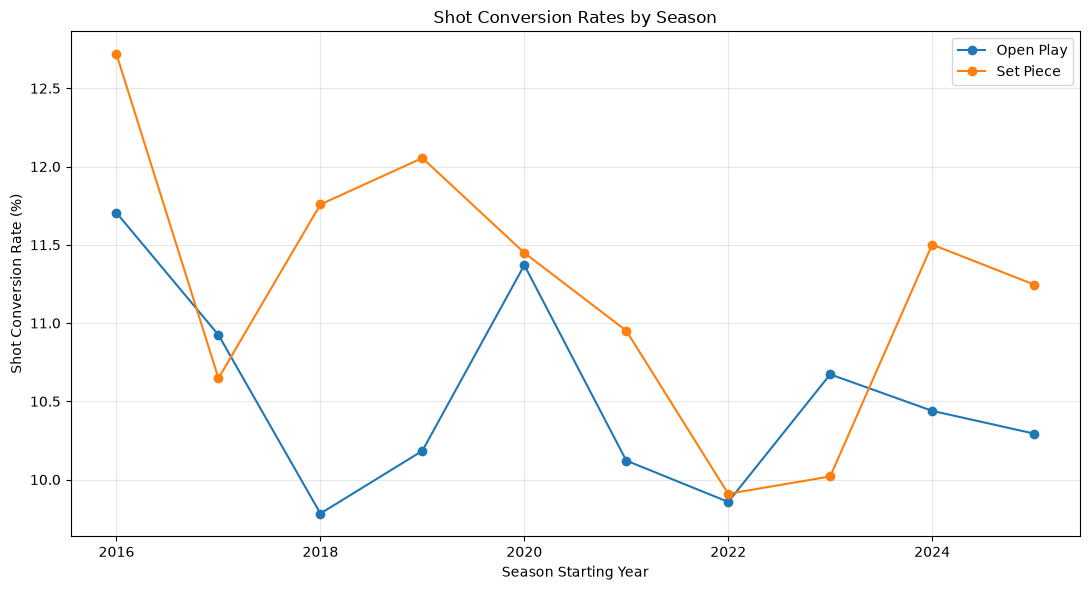

In [39]:
season_trends = (
    main_shots.groupby(["season", "shot_category"])
    .agg(
        Shots=("event_id", "count"),
        Goals=("is_goal", "sum"),
        xG=("xg", "sum")
    )
    .reset_index()
)

season_trends["Conversion_Rate"] = (
    season_trends["Goals"] /
    season_trends["Shots"] * 100
)

# Compare shot conversion rates over time
conversion_trends = season_trends.pivot(
    index="season",
    columns="shot_category",
    values="Conversion_Rate"
)

plt.figure(figsize=(11, 6))

for category in conversion_trends.columns:
    plt.plot(
        2000 + conversion_trends.index.astype(int) // 100,
        conversion_trends[category],
        marker="o",
        label=category
    )

plt.title("Shot Conversion Rates by Season")
plt.xlabel("Season Starting Year")
plt.ylabel("Shot Conversion Rate (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

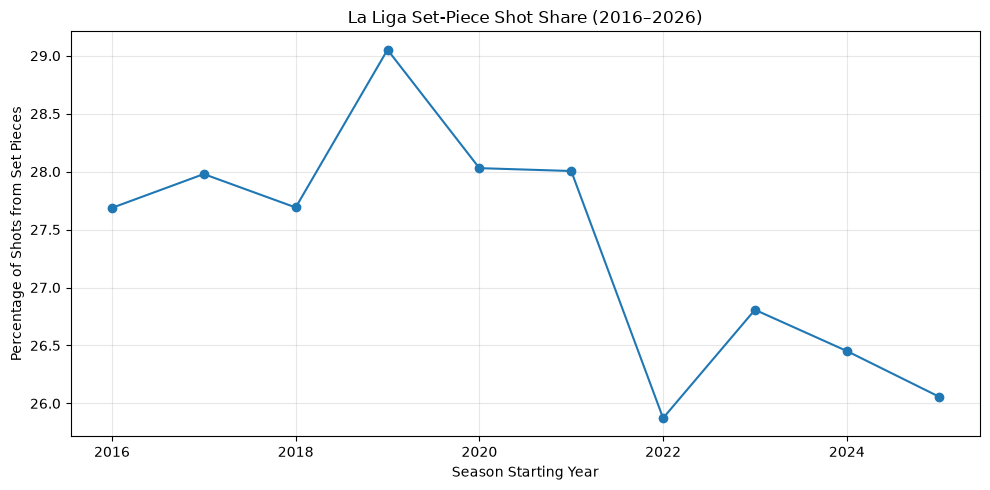

shot_category,Open Play,Set Piece,Set_Piece_Percentage
season,,,
1617,6613,2532,27.69
1718,6600,2564,27.98
1819,6685,2560,27.69
1920,6098,2497,29.05
2021,5831,2271,28.03
2122,6432,2502,28.01
2223,6939,2422,25.87
2324,6812,2495,26.81
2425,6648,2391,26.45


In [40]:
season_shares = (
    main_shots.groupby(["season", "shot_category"])
    .size()
    .unstack(fill_value=0)
)

season_shares["Set_Piece_Percentage"] = (
    season_shares["Set Piece"] /
    (season_shares["Open Play"] + season_shares["Set Piece"]) * 100
)

plt.figure(figsize=(10, 5))

plt.plot(
    2000 + season_shares.index.astype(int) // 100,
    season_shares["Set_Piece_Percentage"],
    marker="o"
)

plt.title("La Liga Set-Piece Shot Share (2016–2026)")
plt.xlabel("Season Starting Year")
plt.ylabel("Percentage of Shots from Set Pieces")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

display(season_shares.round(2))

In [41]:
from scipy.stats import ttest_ind

set_piece_teams = team_stats[
    team_stats["Playstyle"] == "More Set-Piece Dependent"
]["Points_Per_Game"]

open_play_teams = team_stats[
    team_stats["Playstyle"] == "More Open-Play Dependent"
]["Points_Per_Game"]

t_stat, p_value = ttest_ind(
    set_piece_teams,
    open_play_teams,
    equal_var=False
)

print("Set-piece group average PPG:", round(set_piece_teams.mean(), 3))
print("Open-play group average PPG:", round(open_play_teams.mean(), 3))
print("T-statistic:", round(t_stat, 4))
print("P-value:", round(p_value, 4))

if p_value < 0.05:
    print("Statistically significant difference at alpha = 0.05")
else:
    print("No statistically significant difference at alpha = 0.05")

Set-piece group average PPG: 1.2
Open-play group average PPG: 1.535
T-statistic: -5.7679
P-value: 0.0
Statistically significant difference at alpha = 0.05


In [42]:
print("LA LIGA SHOT ANALYSIS")
print("2016-17 through 2025-26")
print("-" * 45)

print("\nShot conversion rates:")
display(category_stats[
    ["shot_category", "Shots", "Goals", "Conversion_Rate"]
].round(2))

print("\nPlaystyle comparison:")
display(playstyle_results.round(2))

print("\nSet-piece dependence vs points per game:")
print(f"Pearson correlation: {correlation:.3f}")

print("\nStatistical comparison:")
print(f"P-value: {p_value:.4f}")

print("\nSet-piece shot share by season:")
display(season_shares[["Set_Piece_Percentage"]].round(2))

LA LIGA SHOT ANALYSIS
2016-17 through 2025-26
---------------------------------------------

Shot conversion rates:


,shot_category,Shots,Goals,Conversion_Rate
0,Open Play,65672,6911,10.52
1,Set Piece,24706,2774,11.23



Playstyle comparison:


,Teams_Seasons,Avg_Points_Per_Game,Avg_Open_Play_Goals,Avg_Set_Piece_Goals,Avg_Set_Piece_Share
Playstyle,,,,,
More Open-Play Dependent,100,1.53,41.88,13.51,24.40
More Set-Piece Dependent,100,1.20,27.23,14.23,30.83



Set-piece dependence vs points per game:
Pearson correlation: -0.403

Statistical comparison:
P-value: 0.0000

Set-piece shot share by season:


shot_category,Set_Piece_Percentage
season,
1617,27.69
1718,27.98
1819,27.69
1920,29.05
2021,28.03
2122,28.01
2223,25.87
2324,26.81
2425,26.45


# Question 3: Which teams have the largest difference in expected points and actual points?

In [18]:
from scipy.stats import poisson

matchdf = pd.read_csv("esp_shots_2016_2025.csv")

# Use the season starting year (1617 -> 2016)
matchdf["season"] = 2000 + matchdf["season"] // 100

# Preprocessing to handle own goals and xG
matchdf["is_goal"] = (matchdf["is_goal"] & ~matchdf["is_own_goal"]).astype(int)
matchdf["is_own_goal"] = matchdf["is_own_goal"].astype(int)
matchdf["xg_valid"] = matchdf["xg"].where(matchdf["is_own_goal"] == 0, 0)

# One row per team per match
teamGames = (matchdf.groupby(["season", "match_id", "team_id", "team"], as_index=False)
    .agg(xg_for=("xg_valid", "sum"),
         missing_xg=("xg_valid", lambda values: values.isna().any()),
         goals_scored=("is_goal", "sum"),
         own_goals_by=("is_own_goal", "sum")))

# Keep matches where both teams have shot records
complete = teamGames.groupby(["season", "match_id"])["team_id"].transform("nunique") == 2
teamGames = teamGames[complete].copy()

# Gather match stats, including own goals awarded to opponents
singleGame = teamGames.groupby(["season", "match_id"])
xgTotal = singleGame["xg_for"].transform("sum")
ownGoalsTotal = singleGame["own_goals_by"].transform("sum")
goalsTotal = singleGame["goals_scored"].transform("sum") + ownGoalsTotal

teamGames["goals_for"] = teamGames["goals_scored"] + ownGoalsTotal - teamGames["own_goals_by"]
teamGames["goals_against"] = goalsTotal - teamGames["goals_for"]
teamGames["xg_against"] = xgTotal - teamGames["xg_for"]

# Actual match points from reconstructed scores
teamGames["Points"] = np.select(
    [teamGames["goals_for"] > teamGames["goals_against"],
     teamGames["goals_for"] == teamGames["goals_against"]], [3, 1], default=0
)

# Do not calculate expected points for matches with missing xG
complete_xg = ~teamGames.groupby(["season", "match_id"])["missing_xg"].transform("any")
teamGames = teamGames[complete_xg].copy()

# Calculate expected match points from xG using a Poisson goal model
# Expected points = 3 * P(win) + P(draw)
k = np.arange(31)
for_xg = teamGames["xg_for"].to_numpy()[:, None]
against_xg = teamGames["xg_against"].to_numpy()[:, None]
p_win = (poisson.pmf(k, for_xg) * poisson.cdf(k - 1, against_xg)).sum(axis=1)
p_draw = (poisson.pmf(k, for_xg) * poisson.pmf(k, against_xg)).sum(axis=1)
teamGames["xPts"] = 3 * p_win + p_draw

# One row per team per season
seasonTable = (teamGames.groupby(["season", "team_id", "team"], as_index=False)
    .agg(matches=("match_id", "count"),
         actual_points=("Points", "sum"), expected_points=("xPts", "sum"),
         goals_for=("goals_for", "sum"), xg_for=("xg_for", "sum"),
         goals_against=("goals_against", "sum"), xg_against=("xg_against", "sum")))

seasonTable["points_diff"] = seasonTable["actual_points"] - seasonTable["expected_points"]
seasonTable["gf_diff"] = seasonTable["goals_for"] - seasonTable["xg_for"]
seasonTable["ga_diff"] = seasonTable["goals_against"] - seasonTable["xg_against"]
seasonTable["xg_diff"] = seasonTable["xg_for"] - seasonTable["xg_against"]
seasonTable["team_season"] = seasonTable["team"] + " (" + seasonTable["season"].astype(str) + ")"

print("Biggest single season points overperformers:")
display(seasonTable.sort_values("points_diff", ascending=False).head(10).round(1))

print("\nBiggest single season points underperformers:")
display(seasonTable.sort_values("points_diff").head(10).round(1))

print("Note: expected points use a Poisson model; points come from recorded shot-event goals.")

Biggest single season points overperformers:


,season,team_id,team,matches,actual_points,expected_points,goals_for,xg_for,goals_against,xg_against,points_diff,gf_diff,ga_diff,xg_diff,team_season
87,2020,63,Atletico,34,77,52.2,58,43.4,23,34.9,24.8,14.6,-11.9,8.4,Atletico (2020)
49,2018,65,Barcelona,37,86,62.7,86,61.0,32,40.3,23.3,25.0,-8.3,20.7,Barcelona (2018)
47,2018,63,Atletico,38,76,52.9,55,44.3,29,41.4,23.1,10.7,-12.4,2.8,Atletico (2018)
141,2023,52,Real Madrid,36,89,66.1,80,62.8,26,34.6,22.9,17.2,-8.6,28.1,Real Madrid (2023)
27,2017,63,Atletico,37,76,54.0,57,41.9,22,35.6,22.0,15.1,-13.6,6.3,Atletico (2017)
190,2025,65,Barcelona,36,88,66.5,90,71.1,35,44.0,21.5,18.9,-9.0,27.0,Barcelona (2025)
101,2021,52,Real Madrid,33,81,60.2,76,64.7,26,37.7,20.8,11.3,-11.7,27.0,Real Madrid (2021)
28,2017,65,Barcelona,36,87,66.7,92,66.6,29,38.8,20.3,25.4,-9.8,27.8,Barcelona (2017)
159,2023,2783,Girona,35,72,53.4,77,57.2,44,50.4,18.6,19.8,-6.4,6.9,Girona (2023)
110,2021,67,Sevilla,37,70,52.2,51,40.2,27,37.6,17.8,10.8,-10.6,2.6,Sevilla (2021)



Biggest single season points underperformers:


,season,team_id,team,matches,actual_points,expected_points,goals_for,xg_for,goals_against,xg_against,points_diff,gf_diff,ga_diff,xg_diff,team_season
93,2020,824,Eibar,33,24,49.3,26,40.2,44,34.3,-25.3,-14.2,9.7,5.9,Eibar (2020)
31,2017,69,Malaga,38,20,43.3,24,37.1,61,51.2,-23.3,-13.1,9.8,-14.0,Malaga (2017)
156,2023,925,Granada,36,18,39.7,35,40.7,77,56.2,-21.7,-5.7,20.8,-15.5,Granada (2023)
158,2023,1799,Almeria,36,18,39.4,41,43.7,73,62.1,-21.4,-2.7,10.9,-18.4,Almeria (2023)
165,2024,58,Real Valladolid,36,13,34.0,25,34.1,87,63.5,-21.0,-9.1,23.5,-29.4,Real Valladolid (2024)
72,2019,70,Espanyol,35,25,44.1,25,36.1,51,41.9,-19.1,-11.1,9.1,-5.8,Espanyol (2019)
24,2017,59,Deportivo,32,27,46.1,36,44.5,65,42.2,-19.1,-8.5,22.8,2.3,Deportivo (2017)
59,2018,5006,SD Huesca,36,30,48.0,41,50.1,63,52.2,-18.0,-9.1,10.8,-2.1,SD Huesca (2018)
76,2019,825,Leganes,34,32,48.5,26,37.0,46,35.7,-16.5,-11.0,10.3,1.3,Leganes (2019)
115,2021,832,Levante,35,31,47.2,47,47.4,73,51.2,-16.2,-0.4,21.8,-3.9,Levante (2021)


Note: expected points use a Poisson model; points come from recorded shot-event goals.


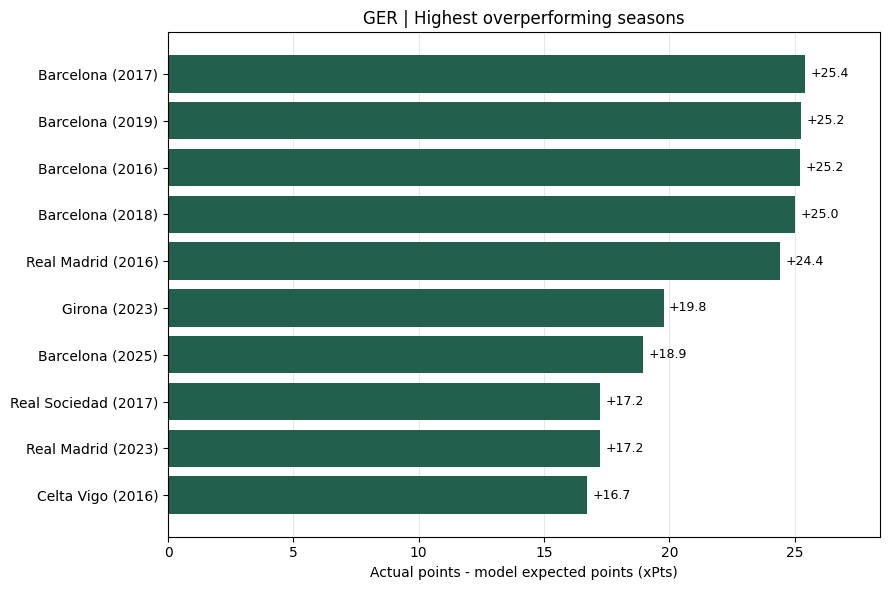

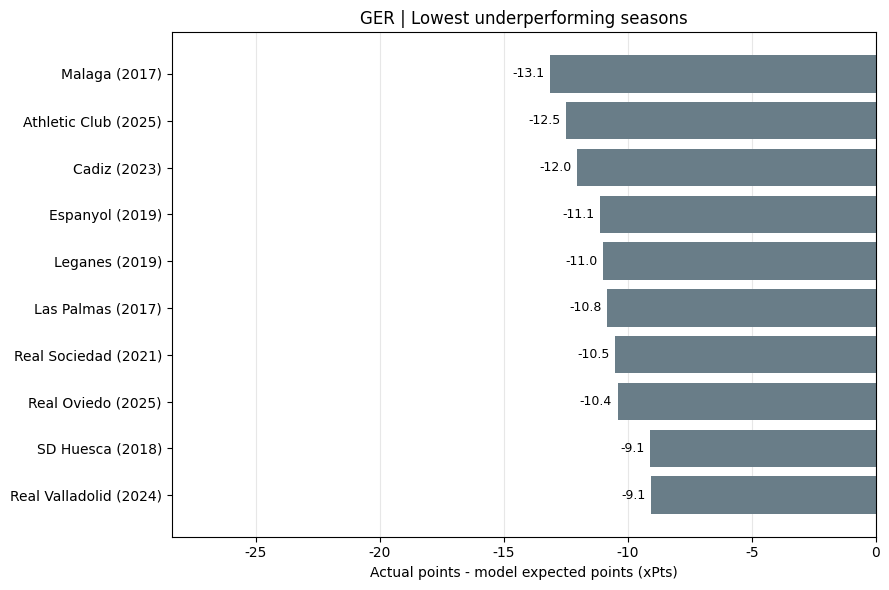

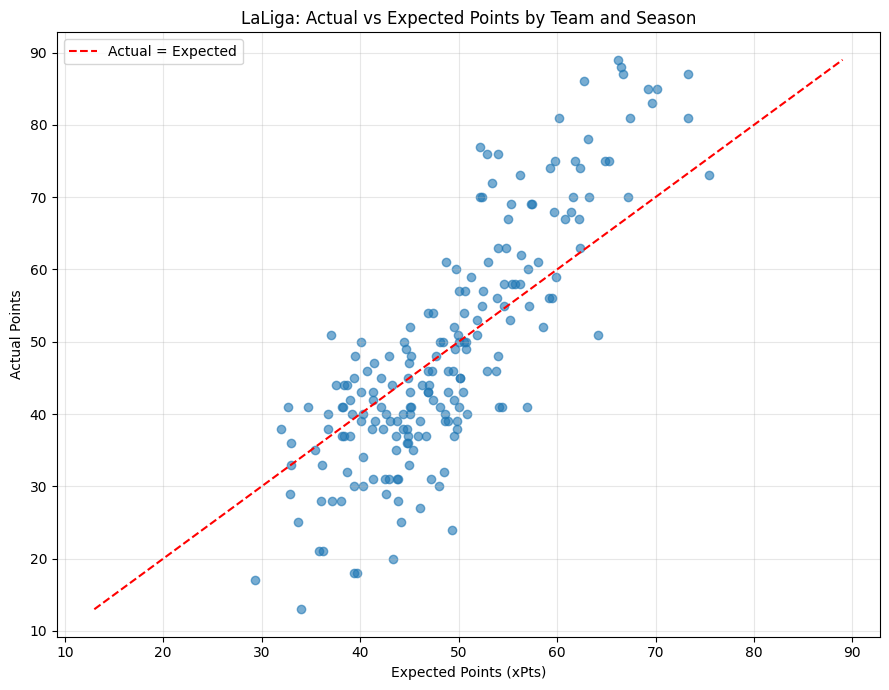

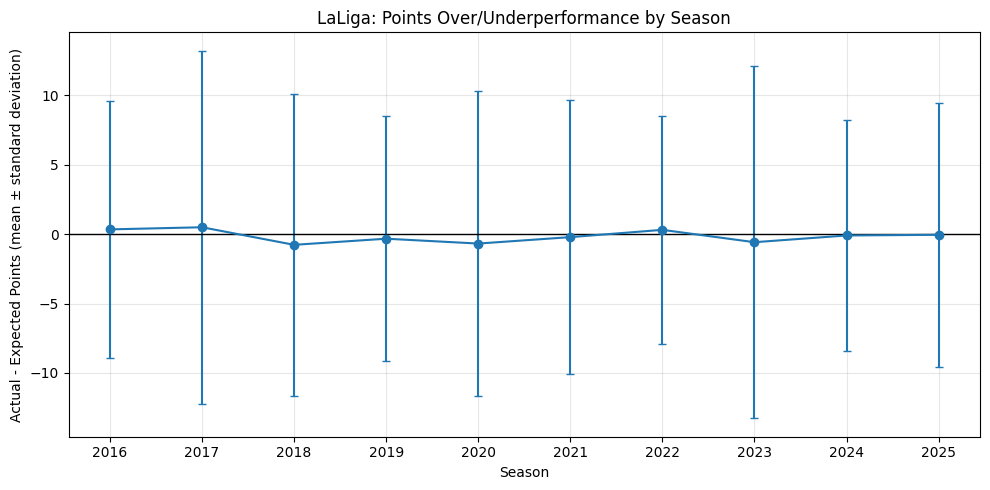

In [19]:
from matplotlib.lines import Line2D
from matplotlib.ticker import MultipleLocator

# Question 3 Graphs

# Graph 1: Largest actual vs expected points differences
season_table = seasonTable[seasonTable["matches"] >= 34].copy()
season_table["season_id"] = "20" + season_table["season"].astype(str).str[2:4]
season_table["label"] = season_table["team"] + " (" + season_table["season_id"] + ")"
season_table["abs_diff"] = season_table["gf_diff"].abs()

n = 10
over_color, under_color = "#22604d", "#697d88ff"

# Largest gains (goals above xG) and largest drops (goals below xG)
top_gains = season_table.nlargest(n, "gf_diff").sort_values("abs_diff")
top_drops = season_table.nsmallest(n, "gf_diff").sort_values("abs_diff")

# Shared axis range so the two charts are comparable
xmax = max(top_gains["abs_diff"].max(), top_drops["abs_diff"].max()) + 3

def draw_chart(data, color, title, xlabel, right_justified=False):
    fig, ax = plt.subplots(figsize=(9, 6))
    bars = ax.barh(data["label"], data["abs_diff"], color=color, zorder=2)
    for i, (bar_len, signed) in enumerate(zip(data["abs_diff"], data["gf_diff"])):
        ax.annotate(f"{signed:+.1f}", xy=(bar_len, i),
                    xytext=(-4 if right_justified else 4, 0), textcoords="offset points",
                    ha="right" if right_justified else "left", va="center", fontsize=9)

    if right_justified:
        ax.set_xlim(xmax, 0)
        ax.xaxis.set_major_formatter(lambda x, pos: f"{-x:g}" if x != 0 else "0")
    else:
        ax.set_xlim(0, xmax)        # zero on the left, bars grow rightward

    ax.set_xlabel(xlabel)
    ax.set_title(title)
    ax.xaxis.set_major_locator(MultipleLocator(5))
    ax.grid(axis="x", alpha=0.3, zorder=0)
    plt.tight_layout()
    plt.show()

draw_chart(top_gains, over_color,
           f"GER | Highest overperforming seasons",
           "Actual points - model expected points (xPts)")

draw_chart(top_drops, under_color,
           f"GER | Lowest underperforming seasons",
           "Actual points - model expected points (xPts)", right_justified=True)


# Graph 2: Actual vs expected points
plt.figure(figsize=(9, 7))
plt.scatter(
    seasonTable["expected_points"],
    seasonTable["actual_points"],
    alpha=0.6
)

limits = [
    min(seasonTable["expected_points"].min(), seasonTable["actual_points"].min()),
    max(seasonTable["expected_points"].max(), seasonTable["actual_points"].max())
]

plt.plot(limits, limits, "r--", label="Actual = Expected")
plt.title("LaLiga: Actual vs Expected Points by Team and Season")
plt.xlabel("Expected Points (xPts)")
plt.ylabel("Actual Points")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# Graph 3: Points differences by season
season_diff = seasonTable.groupby("season")["points_diff"].agg(["mean", "std"])

plt.figure(figsize=(10, 5))
plt.errorbar(
    season_diff.index.astype(str),
    season_diff["mean"],
    yerr=season_diff["std"],
    marker="o",
    capsize=3
)

plt.axhline(0, color="black", linewidth=1)
plt.title("LaLiga: Points Over/Underperformance by Season")
plt.xlabel("Season")
plt.ylabel("Actual - Expected Points (mean ± standard deviation)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()
